# Feature engineering

**Aim:** build a small set of ratio features from credit logic, then test whether they carry more signal than the columns they come from.

The features are chosen before looking at any IV, so the test is fair. They are deterministic (nothing is fitted), so they can be computed on any loan, including the 2015 test year. The kept features go into `src/credit_risk/features.py`.

**Sections**
1. Loading the data
2. The candidate features
3. Do they add signal?
4. Decision

In [3]:
import sys
sys.path.insert(0, "../src")

%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import credit_risk.woe as wo

pd.set_option("display.max_rows", None)
pd.set_option("display.width", 250)

## 1. Loading the data

Train years only. The 2015 test year is not used in this notebook.

In [4]:
train = pd.read_parquet("../data/processed/train.parquet")

# 36-month train loans: the population the WoE rules are fitted on
train36 = wo.fit_population(train)
print(train36.shape)    # expect (337996, 41)

(337996, 41)


## 2. The candidate features

Four ratios, chosen from credit logic. Income of 0 or missing gives NaN.

| Feature | Formula | Idea |
|---|---|---|
| `loan_to_income` | `loan_amnt / annual_inc` | size of the loan relative to income |
| `payment_to_income` | `installment × 12 / annual_inc` | yearly payments on this loan as a share of income |
| `dti_with_loan` | `dti + 100 × payment_to_income` | debt burden after this loan, if `dti` excludes it |
| `revol_bal_to_income` | `revol_bal / annual_inc` | card balances relative to income |



In [12]:
own = 100* train36['installment'] *12/train36['annual_inc'].where(train36['annual_inc']>0)

below= train36['dti']<own
print("share of loans with dti below the loan's own payment ratio:", round(below.mean(), 3))
below.groupby(train36["issue_year"]).mean().round(3)

share of loans with dti below the loan's own payment ratio: 0.135


issue_year
2007    0.332
2008    0.214
2009    0.237
2010    0.204
2011    0.181
2012    0.150
2013    0.135
2014    0.119
dtype: float64

In [13]:
import credit_risk.features as ft

train36 = ft.add_features(train36)

print(train36[ft.NEW_FEATURES].isnull().sum())    # NaN from zero or missing income
train36[ft.NEW_FEATURES].describe().round(3)

loan_to_income         4
payment_to_income      4
dti_with_loan          4
revol_bal_to_income    4
dtype: int64


,loan_to_income,payment_to_income,dti_with_loan,revol_bal_to_income
count,337992.000,337992.000,337992.000,337992.000
mean,0.195,0.079,24.644,0.225
std,0.104,0.043,9.787,0.191
min,0.001,0.000,0.044,0.000
25%,0.114,0.046,17.358,0.104
50%,0.180,0.072,24.129,0.185
75%,0.265,0.106,31.459,0.298
max,1.338,0.542,69.171,7.956


**Result of building the features**
- 4 loans have NaN in every new feature (zero or missing income). `woe.py` fills a missing group this small with the median.
- The new loan adds about 7.9 points on average to `dti` (mean `dti_with_loan` 24.6, mean `dti` about 16.7), so the feature changes every loan's burden.
- A few extreme values at the top (`loan_to_income` up to 1.34, `revol_bal_to_income` up to 7.96) come from very low reported incomes. The top quantile bin absorbs them.
- For 36-month loans, `payment_to_income` is about 0.4 × `loan_to_income`, so the two should be near duplicates.

## 3. Do they add signal?

IV of each new feature, next to the IV of the columns it is built from. All use the same binning as before (10 quantile bins, missing in its own bin), fitted on 36-month train loans.

**Rule of thumb for keeping a feature:** its IV is clearly above the best IV of its own components, and its plot has no reversals. Overlap between the kept features is handled in the correlation step.

In [14]:
# the raw columns the new features are built from, then the new features
parts = ["loan_amnt", "installment", "annual_inc", "dti", "revol_bal"]
test_cols = parts + ft.NEW_FEATURES

rules = wo.fit_woe(train36, features=test_cols)   # same binning rules as woe.py, fitted on train only
wo.iv_summary(rules)

,feature,iv,n_bins,thin_bins
0,annual_inc,0.083127,10,0
1,dti_with_loan,0.076781,10,0
2,payment_to_income,0.063292,10,0
3,dti,0.043966,10,0
4,loan_to_income,0.041868,10,0
5,revol_bal,0.014156,10,0
6,revol_bal_to_income,0.007434,10,0
7,loan_amnt,0.005568,10,0
8,installment,0.003926,10,0


In [15]:
# rank correlation: how much do the new features overlap with their parts and with each other?
train36[test_cols].corr(method="spearman").round(2)

,loan_amnt,installment,annual_inc,dti,revol_bal,loan_to_income,payment_to_income,dti_with_loan,revol_bal_to_income
loan_amnt,1.00,0.99,0.47,0.03,0.49,0.60,0.59,0.26,0.21
installment,0.99,1.00,0.45,0.04,0.48,0.61,0.61,0.28,0.22
annual_inc,0.47,0.45,1.00,-0.21,0.41,-0.36,-0.37,-0.33,-0.18
dti,0.03,0.04,-0.21,1.00,0.24,0.23,0.24,0.90,0.40
revol_bal,0.49,0.48,0.41,0.24,1.00,0.16,0.15,0.26,0.78
loan_to_income,0.60,0.61,-0.36,0.23,0.16,1.00,0.99,0.60,0.41
payment_to_income,0.59,0.61,-0.37,0.24,0.15,0.99,1.00,0.61,0.41
dti_with_loan,0.26,0.28,-0.33,0.90,0.26,0.60,0.61,1.00,0.50
revol_bal_to_income,0.21,0.22,-0.18,0.40,0.78,0.41,0.41,0.50,1.00


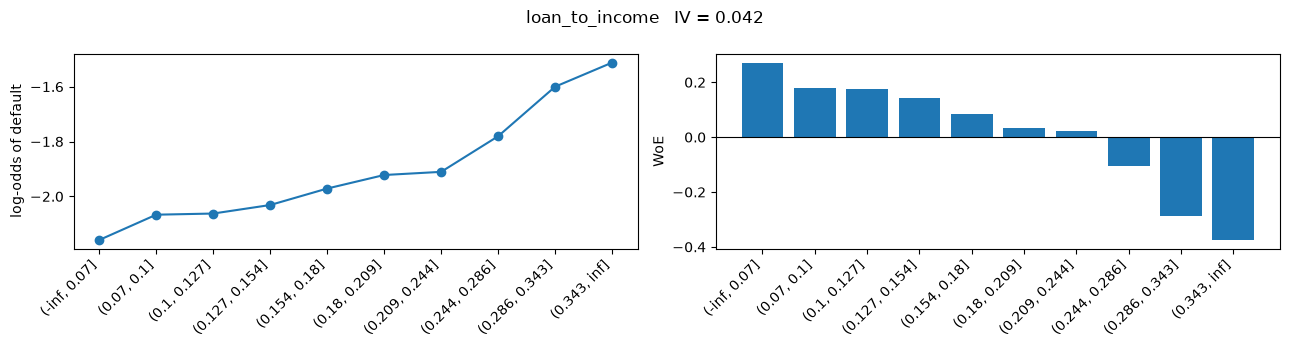

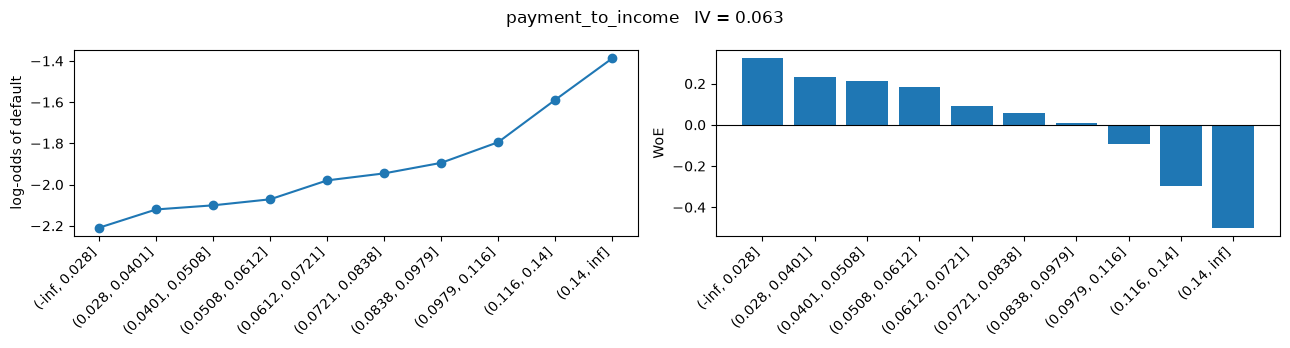

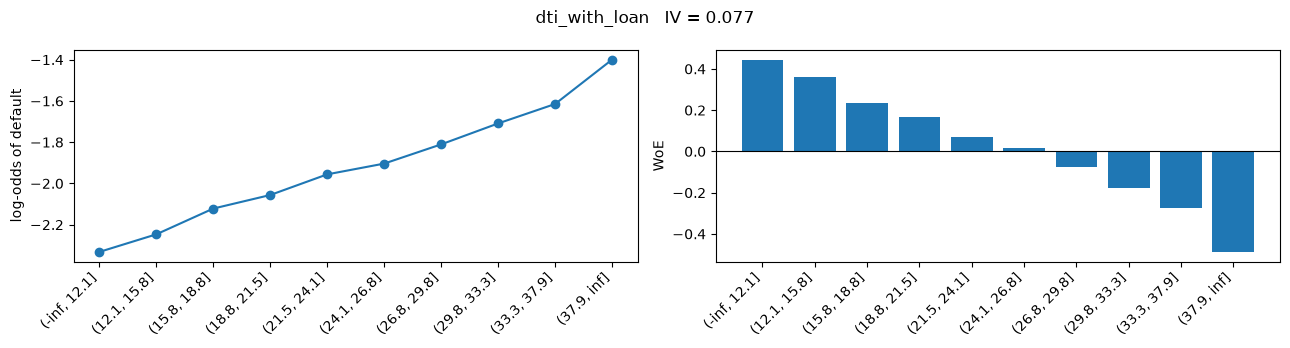

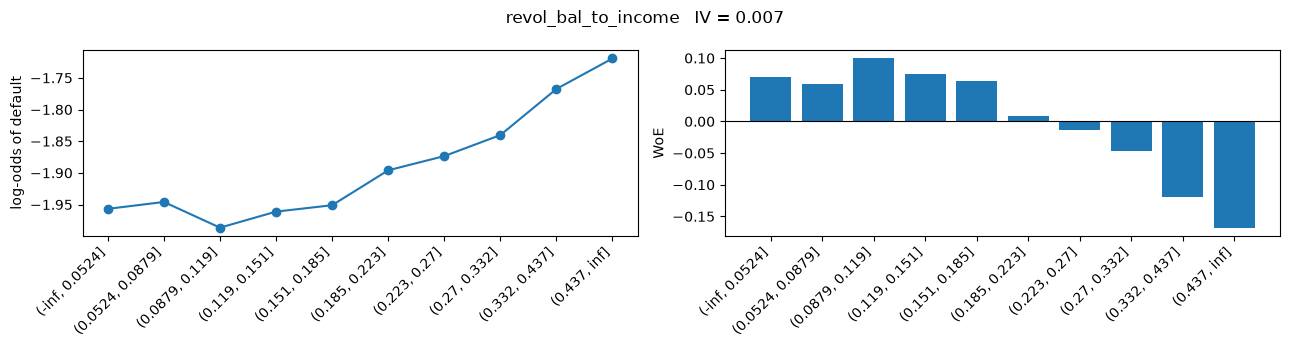

In [16]:
def plot_rule(rules, col):
    t = rules[col]["table"].copy()
    t["log_odds"] = np.log(t["defaults"] / t["non_defaults"])

    edges = rules[col].get("edges")            # bin ranges, for numeric features
    if edges is not None:
        names = {str(i): f"({edges[i]:.3g}, {edges[i + 1]:.3g}]" for i in range(len(edges) - 1)}
        t.index = [names.get(i, i) for i in t.index]

    pos = range(len(t))
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.5))
    ax1.plot(pos, t["log_odds"], marker="o")   # left: log-odds of default by bin
    ax1.set_ylabel("log-odds of default")
    ax2.bar(pos, t["woe"])                     # right: WoE by bin, 0 = average
    ax2.axhline(0, color="black", linewidth=0.8)
    ax2.set_ylabel("WoE")

    for ax in (ax1, ax2):
        ax.set_xticks(pos)
        ax.set_xticklabels(t.index, rotation=45, ha="right")

    fig.suptitle(f"{col}   IV = {t['iv'].sum():.3f}")
    plt.tight_layout()
    plt.show()


for col in ft.NEW_FEATURES:
    plot_rule(rules, col)

In [17]:
# do the kept features just repeat int_rate? loan_to_income (no rate in it) is the control
check = train36[["int_rate", "payment_to_income", "dti_with_loan"]].copy()
check["loan_to_income"] = train36["loan_amnt"] / train36["annual_inc"].where(train36["annual_inc"] > 0)
check.corr(method="spearman").round(2)

,int_rate,payment_to_income,dti_with_loan,loan_to_income
int_rate,1.00,0.14,0.18,0.05
payment_to_income,0.14,1.00,0.61,0.99
dti_with_loan,0.18,0.61,1.00,0.60
loan_to_income,0.05,0.99,0.60,1.00


**Check: do the kept features repeat `int_rate`?**
- Spearman correlation with `int_rate`: `payment_to_income` 0.14, `dti_with_loan` 0.18, and 0.05 for `loan_to_income`, which has no rate in it.
- All are weak, so neither kept feature repeats `int_rate`. On 36-month loans the only difference between `payment_to_income` and `loan_to_income` is the interest rate, which explains why the first has the higher IV.
- Whether they add anything beyond `int_rate` is tested in the regression (VIF and coefficient signs).

## 4. Decision

- Keep `dti_with_loan` and `payment_to_income` as candidates for the selection step.
- Drop `loan_to_income` (0.99 correlated with `payment_to_income`, lower IV) and `revol_bal_to_income` (weaker than `revol_bal`).

**Why**
- `dti_with_loan` is 75% above `dti` (0.077 against 0.044) and has the cleanest plot.
- No ratio beats `annual_inc` (0.083) on IV alone. Univariate IV can't show whether a ratio adds information beyond its parts, so the final test is the 2015 AUC with and without them in the regression.
- Both kept features have a correlation with `int_rate` of 0.18 or below.